# H4 solver comparison

This notebook mirrors `examples/scripts/02_h4_compare_solvers.py`.
It compares the three solver families on a very small hydrogen chain.

Goal:
- compare solver behavior while staying below the chemistry rule-of-thumb target of `1 mEh`

What to notice:
- the dashed horizontal line marks the `1 mEh` target
- on this small case, all three solvers land below that line

Project status note:
- the current large-active-space production answer in this repo is the Quantum Package path with `connected_sd_fullq`, `abs_residual`, `ccik_thick`, and fixed-budget tuning of `fixed_store_keep` and `fixed_propagate_keep`
- these teaching notebooks stay small on purpose; they explain the ideas before the large-`N2` benchmark workflow

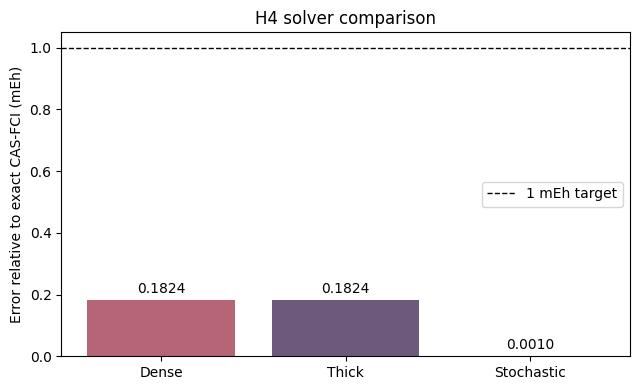

{'e_fci_total': -1.9961503255188093,
 'e_dense_total': -1.9959679631524176,
 'e_thick_total': -1.9959679631524176,
 'e_stochastic_total': -1.996149305735361,
 'dense_delta_mEh': 0.18236236639168624,
 'thick_delta_mEh': 0.18236236639168624,
 'stochastic_delta_mEh': 0.0010197834483527402}

In [1]:
import importlib.util
from pathlib import Path

import matplotlib.pyplot as plt

repo_root = Path.cwd()
if not (repo_root / "examples" / "scripts").exists():
    repo_root = repo_root.parent.parent
script_path = repo_root / "examples" / "scripts" / "02_h4_compare_solvers.py"
spec = importlib.util.spec_from_file_location("h4_example", script_path)
module = importlib.util.module_from_spec(spec)
assert spec is not None and spec.loader is not None
spec.loader.exec_module(module)

result = module.run_example()

fig, ax = plt.subplots(figsize=(6.5, 4))
labels = ["Dense", "Thick", "Stochastic"]
errors = [
    result["dense_delta_mEh"],
    result["thick_delta_mEh"],
    result["stochastic_delta_mEh"],
]
colors = ["#b56576", "#6d597a", "#355070"]
bars = ax.bar(labels, errors, color=colors)
ax.set_ylabel("Error relative to exact CAS-FCI (mEh)")
ax.set_title("H4 solver comparison")
ax.axhline(1.0, color="black", linestyle="--", linewidth=1, label="1 mEh target")
ax.bar_label(bars, fmt="%.4f", padding=3)
ax.legend()
plt.tight_layout()
plt.show()
result

## Where this fits in the project

This notebook is a small-system teaching example. The current production benchmark result for larger `N2` active spaces uses:

- Quantum Package backend
- `connected_sd_fullq`
- `abs_residual`
- `ccik_thick`
- `fixed_budget` compression

The detailed benchmark summary is in `docs/fixed_budget_results.md`.